## Tahap 2 & 3: Data Loading, Preprocessing, dan Exploratory Data Analysis (EDA)

Dokumen ini berisi penjelasan untuk setiap tahapan pemrosesan awal data teks (tweet) terkait Karhutla Kalimantan 2026. Pemrosesan ini wajib dilakukan sebelum kita melatih model analisis sentimen.

### Penjelasan Cell 1: Import Library & Load Data
Pada blok ini, kita mempersiapkan *environment* kerja dan memuat dataset mentah.
* **Tujuan**: Membaca file JSON (`dataset_karhutla_kalimantan.json`) yang berisi data tarikan dari X (Twitter) ke dalam format tabel (Pandas DataFrame) agar mudah diolah.
* **Proses**: Kita menggunakan `sys.path.append` untuk memanggil modul kustom `cleaner.py` dari folder `src/preprocessing/`. Fungsi `pd.read_json()` mengubah data JSON menjadi tabel, lalu `.head()` digunakan untuk memverifikasi apakah kolom-kolom penting (seperti `full_text` atau `text`) sudah terbaca dengan benar beserta metadata lainnya (seperti `retweetCount`, `likeCount`).

### Penjelasan Cell 2: Eksekusi Preprocessing (Pembersihan Teks Dasar)
Data teks dari media sosial sangat kotor. Blok ini bertugas membersihkannya.
* **Tujuan**: Menghapus elemen-elemen *noise* (gangguan) pada teks agar mesin hanya fokus pada kata-kata yang bermakna.
* **Proses**: Mengaplikasikan fungsi `clean_tweet_text` yang sudah dibuat di `cleaner.py`. Fungsi ini menggunakan *Regular Expression* (Regex) untuk melakukan:
  1. *Case Folding*: Mengubah semua huruf menjadi huruf kecil.
  2. Menghapus URL/Tautan HTTP.
  3. Menghapus *Mention* (contoh: `@jokowi`, `@bnpb`).
  4. Menghapus angka dan tanda baca (!, ?, ,, .).
  5. Menghapus spasi ganda.
* **Hasil Akhir**: Data bersih disimpan di kolom baru `clean_text` dan di-*export* ke folder `processed` agar kita memiliki salinan data *checkpoint*.

### Penjelasan Cell 3: Menghapus Stopwords Bahasa Indonesia
Teks yang sudah bersih masih mengandung kata hubung yang tidak memiliki nilai sentimen.
* **Tujuan**: Menghilangkan kata-kata umum (*stopwords*) yang terlalu sering muncul namun tidak memberikan makna pada topik spesifik atau sentimen (contoh: "dan", "di", "yang", "itu").
* **Proses**: Kita menggunakan kamus bawaan dari library `NLTK` (*Natural Language Toolkit*) untuk Bahasa Indonesia, lalu menambahkan daftar kata *slang* (bahasa gaul) kustom seperti "yg", "aja", "sih". Teks kemudian dipecah, difilter, dan disatukan kembali ke dalam kolom `final_text`.
* **Hasil Akhir**: Teks menjadi jauh lebih padat dan hanya berisi kata-kata inti/kata kunci (misal: "bantuan", "sesak", "asap", "omc").

### Penjelasan Cell 4: Visualisasi WordCloud (Exploratory Data Analysis)
Setelah data bersih dan padat, kita perlu melihat gambaran umum dari perbincangan publik.
* **Tujuan**: Memetakan kata-kata yang memiliki frekuensi kemunculan paling tinggi di dalam seluruh dataset. Kata yang lebih sering disebut akan memiliki ukuran font yang lebih besar.
* **Proses**: Menggabungkan seluruh teks dari kolom `final_text` menjadi satu paragraf raksasa. Modul `WordCloud` kemudian menghitung frekuensi kata dan memplotnya menggunakan `matplotlib` dengan tema warna `inferno` (tema warna panas/api yang relevan dengan topik Karhutla).
* **Hasil Akhir**: Sebuah gambar visualisasi *WordCloud* yang secara otomatis disimpan ke direktori `outputs/figures/wordcloud_karhutla.png` sebagai lampiran untuk laporan akhir.

In [3]:
import pandas as pd
import sys
import os

# Menambahkan folder 'src' ke dalam sistem path agar bisa mengimpor modul cleaner
sys.path.append(os.path.abspath(os.path.join('..', 'src')))
from preprocessing.cleaner import clean_tweet_text

# Sesuaikan nama file dengan file JSON yang Anda letakkan di data/raw/
file_path = '../data/raw/dataset_karhutla_kalimantan.json'

# Membaca data JSON
# Catatan: Tergantung struktur JSON-nya, mungkin butuh parameter lines=True jika formatnya JSONL
try:
    df = pd.read_json(file_path)
    print(f"Data berhasil dimuat! Jumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}")
except Exception as e:
    print(f"Terjadi kesalahan saat memuat data: {e}")

# Tampilkan 5 data teratas untuk memastikan kolomnya benar (biasanya ada 'full_text' atau 'text')
df.head()

Data berhasil dimuat! Jumlah baris: 2240, Jumlah kolom: 32


,type,id,url,twitterUrl,text,source,retweetCount,replyCount,likeCount,quoteCount,...,card,place,entities,reply_to_user_results,quoted_tweet_results,quoted_tweet,retweeted_tweet,isConversationControlled,isQuote,searchTermIndex
0,tweet,2114940094620819586,https://x.com/Ghosting8787/status/211494009462...,https://twitter.com/Ghosting8787/status/211494...,Semoga Kalimantan dan wilayah2 yang terdampak ...,,0,0,0,0,...,None,{},{},None,"{'rest_id': '2114703009313911105', 'result': {...","{'type': 'tweet', 'id': '2114703009313911105',...",NaN,False,1.0,0
1,tweet,2114939893810094293,https://x.com/gandhy_v/status/2114939893810094293,https://twitter.com/gandhy_v/status/2114939893...,Karhutla Kalimantan jadi sorotan! Pemerintah m...,,0,0,0,0,...,None,{},"{'hashtags': [{'indices': [211, 237], 'text': ...",None,None,None,NaN,False,NaN,0
2,tweet,2114939636657057930,https://x.com/tahugaksihraw/status/21149396366...,https://twitter.com/tahugaksihraw/status/21149...,Karhutla Kalimantan jadi sorotan! Pemerintah m...,,0,0,0,0,...,None,{},"{'hashtags': [{'indices': [211, 237], 'text': ...",None,None,None,NaN,False,NaN,0
3,tweet,2114935880955879645,https://x.com/inilahdotcom/status/211493588095...,https://twitter.com/inilahdotcom/status/211493...,"14,3 ton bahan semai telah digunakan BNPB untu...",,0,0,0,0,...,None,{},{'urls': [{'display_url': 'inilah.com/pemerint...,None,None,None,NaN,False,NaN,0
4,tweet,2114935664240378348,https://x.com/inggarooong/status/2114935664240...,https://twitter.com/inggarooong/status/2114935...,"Beberapa minggu ini, tiap tahajjud selalu mint...",,0,0,0,0,...,None,{},{},None,None,None,NaN,False,NaN,0


In [4]:
# Asumsi kolom teks bernama 'full_text' (Silakan ubah jika di JSON Anda namanya 'text' atau 'tweet')
if 'full_text' in df.columns:
    col_name = 'full_text'
elif 'text' in df.columns:
    col_name = 'text'
else:
    print("Kolom teks tidak ditemukan, periksa nama kolom df.head() di atas.")

# Aplikasikan fungsi pembersihan
print("Memulai proses pembersihan teks...")
df['clean_text'] = df[col_name].apply(clean_tweet_text)

# Simpan data yang sudah dibersihkan ke folder processed agar tidak perlu diulang-ulang
output_path = '../data/processed/cleaned_dataset_karhutla.csv'
df.to_csv(output_path, index=False)

print(f"Proses selesai! Data bersih disimpan di: {output_path}")
df[['clean_text']].head()

Memulai proses pembersihan teks...
Proses selesai! Data bersih disimpan di: ../data/processed/cleaned_dataset_karhutla.csv


,clean_text
0,semoga kalimantan dan wilayah yang terdampak k...
1,karhutla kalimantan jadi sorotan pemerintah me...
2,karhutla kalimantan jadi sorotan pemerintah me...
3,ton bahan semai telah digunakan bnpb untuk ope...
4,beberapa minggu ini tiap tahajjud selalu minta...


In [5]:
import nltk
from nltk.corpus import stopwords

# Download kamus stopwords bahasa Indonesia dari NLTK
nltk.download('stopwords')
list_stopwords = set(stopwords.words('indonesian'))

# Tambahkan kata slang/informal yang sering muncul di Twitter namun tidak bermakna
custom_stopwords = {'yg', 'di', 'ke', 'dari', 'ini', 'itu', 'dan', 'untuk', 'ada', 'pada', 'aja', 'ya', 'sih', 'kalo', 'nya', 'jadi'}
list_stopwords.update(custom_stopwords)

def remove_stopwords(text):
    words = str(text).split()
    # Filter kata yang tidak ada di dalam list stopwords
    return ' '.join([word for word in words if word not in list_stopwords])

print("Memulai penghapusan stopwords...")
df['final_text'] = df['clean_text'].apply(remove_stopwords)

# Update file CSV dengan teks final
df.to_csv(output_path, index=False)
print("Penghapusan stopwords selesai dan disimpan!")
df[['clean_text', 'final_text']].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/elsandro/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Memulai penghapusan stopwords...
Penghapusan stopwords selesai dan disimpan!


,clean_text,final_text
0,semoga kalimantan dan wilayah yang terdampak k...,semoga kalimantan wilayah terdampak karhutla p...
1,karhutla kalimantan jadi sorotan pemerintah me...,karhutla kalimantan sorotan pemerintah mengera...
2,karhutla kalimantan jadi sorotan pemerintah me...,karhutla kalimantan sorotan pemerintah mengera...
3,ton bahan semai telah digunakan bnpb untuk ope...,ton bahan semai bnpb operasi modifikasi cuaca ...
4,beberapa minggu ini tiap tahajjud selalu minta...,minggu tahajjud allah turunin hujan tp kaliman...


Membuat visualisasi WordCloud...
Gambar WordCloud berhasil disimpan di: ../outputs/figures/wordcloud_karhutla.png


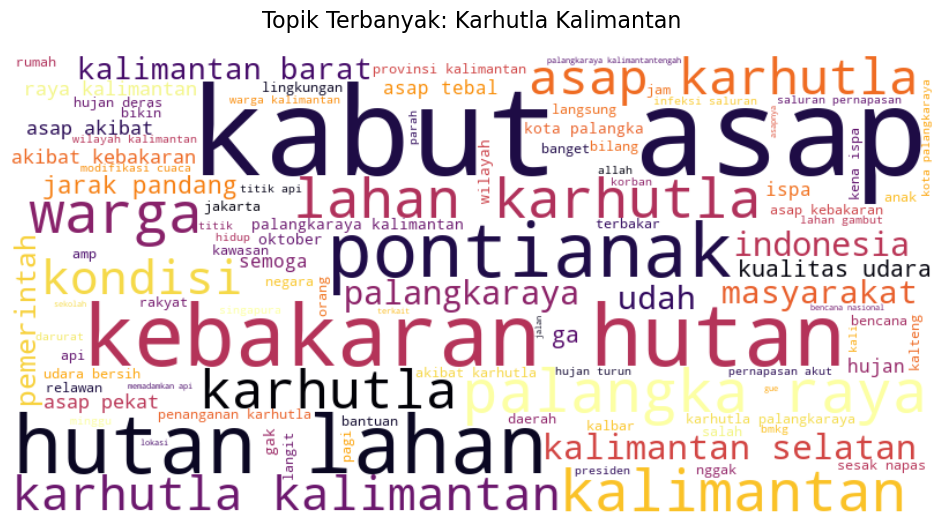

In [7]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Menggabungkan semua teks yang sudah bersih
all_text = ' '.join(df['final_text'].dropna())

print("Membuat visualisasi WordCloud...")
wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color='white', 
    colormap='inferno', # Menggunakan tema warna api/panas cocok untuk topik Karhutla
    max_words=100
).generate(all_text)

# Menampilkan WordCloud
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Topik Terbanyak: Karhutla Kalimantan', fontsize=16, pad=20)

# Menyimpan gambar otomatis ke folder outputs yang sudah kita buat
fig_path = '../outputs/figures/wordcloud_karhutla.png'
plt.savefig(fig_path, bbox_inches='tight')
print(f"Gambar WordCloud berhasil disimpan di: {fig_path}")

plt.show()